# Moduł 2.3 - EEGNet-8,2 (Lawhern i in., 2018): trening LOSO

**Źródła:**
- Lawhern V.J. i in. (2018). [*EEGNet: a compact convolutional neural network for EEG-based brain-computer interfaces*](https://doi.org/10.1088/1741-2552/aace8c), *Journal of Neural Engineering* 15(5), 056013. [Kod autorów](https://github.com/vlawhern/arl-eegmodels/blob/master/EEGModels.py).
- Lotte F. i in. (2018). [*A review of classification algorithms for EEG-based brain–computer interfaces: a 10 year update*](https://doi.org/10.1088/1741-2552/aab2f2), *JNE* 15(3), 031005.
- Ang K.K. i in. (2008). [*Filter Bank Common Spatial Pattern*](https://doi.org/10.1109/IJCNN.2008.4634130), IJCNN, 2390–2397 — klasyczny model odniesienia.
- Blankertz B. i in. (2008). [*Optimizing Spatial Filters for Robust EEG Single-Trial Analysis*](https://doi.org/10.1109/MSP.2008.4408441), *IEEE Signal Processing Magazine* 25(1), 41–56 — tło CSP.

In [ ]:
from pathlib import Path
import copy
import hashlib
import json
import os
import platform
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from IPython.display import display
import sklearn
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
)

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

# ===== KONFIGURACJA =====
DATA_BASE = Path.cwd() / "dane_eegmmidb"
MANIFEST_PATH = None   # None = ostatni zestaw modułu 1;
RESULTS_BASE = Path.cwd() / "wyniki_modeli" / "EEGNet82"
VERIFY_FILE_HASHES = True

# ===== EEGNet-8,2 =====
F1, D, F2 = 8, 2, 16
TEMPORAL_KERNEL, SEPARABLE_KERNEL = 64, 16
DROPOUT = 0.50
MAX_NORM_SPATIAL, MAX_NORM_DENSE = 1.0, 0.25

# ===== TRENING =====
SEED = 42
MAX_EPOCHS = 80       
PATIENCE = 12         
MIN_DELTA = 1e-4
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.0
REFIT_ON_ALL_NON_TEST = True  
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MICROVOLT_SCALE = 1e6  
NORMALIZATION_EPS_UV = 1e-3  

# ===== PRÓG i zapis =====
TUNE_THRESHOLD = False
DEFAULT_THRESHOLD = 0.50
MIN_VALIDATION_RECALL = 0.20
MIN_VALIDATION_POSITIVES = 3
SAVE_MODELS = True
SHOW_PLOTS = True
SAVE_PLOTS = True
TEST_SUBJECT_TO_SHOW = None
N_SAMPLES = 10

# Test wydajności: None = pełne LOSO, 
MAX_FOLDS = None

assert F1 == 8 and D == 2 and F2 == 16
assert MIN_DELTA >= 0 and MAX_EPOCHS >= 1 and PATIENCE >= 1 and BATCH_SIZE >= 2
assert LEARNING_RATE > 0 and 0 <= DROPOUT < 1
assert 0 < DEFAULT_THRESHOLD < 1 and 0 <= MIN_VALIDATION_RECALL <= 1
assert N_SAMPLES >= 1
assert MAX_FOLDS is None or MAX_FOLDS >= 1
print("Python:", platform.python_version(), "| Torch:", torch.__version__,
      "| sklearn:", sklearn.__version__, "| Device:", DEVICE)

Python: 3.12.12 | Torch: 2.9.0+cu128 | sklearn: 1.9.1 | Device: cuda


## 1. Wczytywanie dokładnie tych samych danych i foldów LOSO

In [2]:
def read_json(path):
    with Path(path).open(encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


def stable_hash(payload, size=12):
    return hashlib.sha256(json.dumps(payload, ensure_ascii=False, sort_keys=True)
                          .encode("utf-8")).hexdigest()[:size]


if MANIFEST_PATH is None:
    pointer = read_json(DATA_BASE / "ostatni_zestaw.json")
    manifest_path = (DATA_BASE / pointer["manifest_relative_path"]).resolve()
else:
    manifest_path = Path(MANIFEST_PATH).expanduser().resolve()
manifest = read_json(manifest_path)
if manifest.get("schema_version") != "1.0":
    raise ValueError("Nieobsługiwana wersja manifestu danych z modułu 1.")
dataset_dir = manifest_path.parent
for name, info in manifest["files"].items():
    path = dataset_dir / info["path"]
    if not path.is_file():
        raise FileNotFoundError(path)
    if VERIFY_FILE_HASHES and sha256_file(path) != info["sha256"]:
        raise ValueError(f"Niezgodna suma SHA-256 pliku {name}: {path}")

X_all = np.load(dataset_dir / manifest["files"]["X"]["path"], mmap_mode="r")
y_all = np.load(dataset_dir / manifest["files"]["y"]["path"], mmap_mode="r")
groups = np.load(dataset_dir / manifest["files"]["groups"]["path"], mmap_mode="r")
epoch_run = np.load(dataset_dir / manifest["files"]["runs"]["path"], mmap_mode="r")
splits = read_json(dataset_dir / manifest["files"]["splits"]["path"])
SUBJECT_IDS = list(map(int, manifest["subject_ids"]))
CLASS_NAMES = {int(k): value for k, value in manifest["labels"].items()}
POSITIVE_LABEL = int(manifest["positive_label"])

if X_all.dtype != np.float32 or X_all.ndim != 3 or list(X_all.shape) != manifest["X_shape"]:
    raise ValueError("X.npy: oczekiwano float32 o wymiarach [epoki, kanały, próbki].")
if not len(X_all) == len(y_all) == len(groups) == len(epoch_run):
    raise ValueError("Niespójna liczba epok między tablicami.")
if y_all.dtype != np.int8 or groups.dtype != np.int16 or epoch_run.dtype != np.int8:
    raise ValueError("Niespójne typy danych w y/groups/runs.")
if np.unique(groups).tolist() != SUBJECT_IDS or set(np.unique(y_all).tolist()) != {1, 2}:
    raise ValueError("Niespójne etykiety lub identyfikatory uczestników.")
if POSITIVE_LABEL != 2 or manifest["signal_unit"] != "V":
    raise ValueError("Oczekiwano T2=2 i jednostek sygnału V.")
if splits["dataset_id"] != manifest["dataset_id"]:
    raise ValueError("Podziały LOSO nie należą do tego zestawu danych.")
if [int(f["test_subject"]) for f in splits["folds"]] != SUBJECT_IDS:
    raise ValueError("Foldy LOSO nie obejmują wszystkich osób w oczekiwanej kolejności.")
for fold in splits["folds"]:
    a, b, c = (set(map(int, fold[key])) for key in
               ("train_subjects_internal", "validation_subjects", "test_subjects"))
    if a & b or a & c or b & c or a | b | c != set(SUBJECT_IDS):
        raise ValueError(f"Niepoprawny podział osób w foldzie {fold['fold']}.")
    if c != {int(fold["test_subject"])}:
        raise ValueError("Fold ma nieprawidłowego testowego uczestnika.")

N_CHANNELS, N_TIMES = map(int, X_all.shape[1:])
SFREQ = float(manifest["preprocessing"]["target_sfreq"])
if N_CHANNELS < 2 or N_TIMES < 32:
    raise ValueError("Za mało kanałów/próbek dla EEGNet-8,2.")
if not np.isclose(SFREQ, 128.0):
    warnings.warn("EEGNet-8,2 z kernLength=64 bazuje na sygnale 128 Hz; "
                  "tu ustawiono inną częstotliwość w module 1.")
if set(manifest["task_types"]) == {"motor_imagery", "motor_execution"}:
    warnings.warn("W modułach porównywane są łącznie motor execution i motor imagery. "
                  "Wnioski nie mogą dotyczyć wyłącznie imagery.")

SELECTED_FOLDS = splits["folds"][:MAX_FOLDS] if MAX_FOLDS else splits["folds"]
IS_FULL_LOSO = len(SELECTED_FOLDS) == len(SUBJECT_IDS)
print("Zestaw:", manifest["dataset_id"], "| X:", X_all.shape,
      "| uczestników:", len(SUBJECT_IDS), "| foldów:", len(SELECTED_FOLDS))
print("Klasy:", CLASS_NAMES, "| rodzaje zadań:", manifest["task_types"])
print("Pełne LOSO:", IS_FULL_LOSO, "| sample rate:", SFREQ, "Hz")

Zestaw: 0a8da1dbe454 | X: (9844, 64, 321) | uczestników: 109 | foldów: 109
Klasy: {1: 'lewa dłoń', 2: 'prawa dłoń'} | rodzaje zadań: ['motor_execution', 'motor_imagery']
Pełne LOSO: True | sample rate: 128.0 Hz


/tmp/ipykernel_15443/3628343970.py:74: UserWarning: W modułach porównywane są łącznie motor execution i motor imagery. Wnioski nie mogą dotyczyć wyłącznie imagery.
  warnings.warn("W modułach porównywane są łącznie motor execution i motor imagery. "


## 2. Architektura EEGNet-8,2, skalowanie i kontrola braku leakage

In [ ]:
class EEGNet82(nn.Module):
    """EEGNet-8,2 / Lawhern 2018; przyjmuje [batch,1,C,T], zwraca logity 2 klas."""
    def __init__(self, channels, times, dropout=DROPOUT):
        super().__init__()
        self.temporal_pad = nn.ZeroPad2d((TEMPORAL_KERNEL // 2 - 1,
                                          TEMPORAL_KERNEL // 2, 0, 0))
        self.temporal = nn.Conv2d(1, F1, (1, TEMPORAL_KERNEL), bias=False)
        self.bn1 = nn.BatchNorm2d(F1, eps=1e-3, momentum=0.01)
        self.spatial = nn.Conv2d(F1, F1 * D, (channels, 1), groups=F1, bias=False)
        self.bn2 = nn.BatchNorm2d(F1 * D, eps=1e-3, momentum=0.01)
        self.activation1 = nn.ELU()
        self.pool1 = nn.AvgPool2d((1, 4))
        self.drop1 = nn.Dropout(dropout)
        self.sep_pad = nn.ZeroPad2d((SEPARABLE_KERNEL // 2 - 1,
                                     SEPARABLE_KERNEL // 2, 0, 0))
        self.sep_depth = nn.Conv2d(F1 * D, F1 * D, (1, SEPARABLE_KERNEL),
                                   groups=F1 * D, bias=False)
        self.sep_point = nn.Conv2d(F1 * D, F2, (1, 1), bias=False)
        self.bn3 = nn.BatchNorm2d(F2, eps=1e-3, momentum=0.01)
        self.activation2 = nn.ELU()
        self.pool2 = nn.AvgPool2d((1, 8))
        self.drop2 = nn.Dropout(dropout)
        self.classifier = nn.Linear(F2 * (times // 32), 2)

    def forward(self, x):
        x = self.bn1(self.temporal(self.temporal_pad(x)))
        x = self.drop1(self.pool1(self.activation1(self.bn2(self.spatial(x)))))
        x = self.sep_point(self.sep_depth(self.sep_pad(x)))
        x = self.drop2(self.pool2(self.activation2(self.bn3(x))))
        return self.classifier(x.flatten(1))

    @torch.no_grad()
    def apply_max_norm(self):
        for param, limit in ((self.spatial.weight, MAX_NORM_SPATIAL),
                             (self.classifier.weight, MAX_NORM_DENSE)):
            norms = torch.linalg.vector_norm(param.reshape(param.shape[0], -1),
                                              dim=1).clamp_min(1e-12)
            scale = (limit / norms).clamp(max=1.0)
            param.mul_(scale.reshape(-1, *([1] * (param.ndim - 1))))


class EpochDataset(Dataset):
    """Czyta pojedyncze epoki z memmap; normalizacja po stronie treningu."""
    def __init__(self, X, y, indices, mean_uv, std_uv):
        self.X, self.y = X, y
        self.indices = np.asarray(indices, dtype=np.int64)
        self.mean = np.asarray(mean_uv, dtype=np.float32)[:, None]
        self.std = np.asarray(std_uv, dtype=np.float32)[:, None]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        idx = int(self.indices[position])
        signal_uv = np.asarray(self.X[idx], dtype=np.float32) * MICROVOLT_SCALE
        signal = (signal_uv - self.mean) / self.std
        target = 0 if int(self.y[idx]) == 1 else 1
        return torch.from_numpy(signal[None, ...].copy()), target


def train_channel_stats(indices, chunk_size=128):
    """Średnia i odchylenie *per kanał* z samego treningu (float64, w strumieniu)."""
    idx = np.asarray(indices, dtype=np.int64)
    sums = np.zeros(N_CHANNELS, dtype=np.float64)
    sums_sq = np.zeros(N_CHANNELS, dtype=np.float64)
    for offset in range(0, len(idx), chunk_size):
        block = np.asarray(X_all[idx[offset:offset+chunk_size]], dtype=np.float64)
        block *= MICROVOLT_SCALE
        sums += block.sum(axis=(0, 2))
        sums_sq += np.square(block).sum(axis=(0, 2))
    n = len(idx) * N_TIMES
    mean = sums / n
    var = np.maximum(sums_sq / n - mean**2, 0.0)
    std = np.maximum(np.sqrt(var), NORMALIZATION_EPS_UV)
    return mean.astype(np.float32), std.astype(np.float32)


def make_loader(indices, mean, std, *, shuffle, seed):
    ds = EpochDataset(X_all, y_all, indices, mean, std)
    generator = torch.Generator().manual_seed(int(seed))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=(DEVICE.type == "cuda"),
                      generator=generator)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


def run_one_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_count = 0.0, 0, 0
    loss_func = nn.CrossEntropyLoss()
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(X_batch)
            loss = loss_func(logits, y_batch)
            if training:
                loss.backward()
                optimizer.step()
                model.apply_max_norm()
        total_loss += float(loss.detach()) * len(y_batch)
        total_correct += int((logits.detach().argmax(dim=1) == y_batch).sum())
        total_count += len(y_batch)
    return total_loss / total_count, total_correct / total_count


def fit_with_early_stopping(train_idx, val_idx, *, seed):
    mean_uv, std_uv = train_channel_stats(train_idx)
    train_loader = make_loader(train_idx, mean_uv, std_uv, shuffle=True, seed=seed)
    val_loader = make_loader(val_idx, mean_uv, std_uv, shuffle=False, seed=seed)
    set_seed(seed)
    model = EEGNet82(N_CHANNELS, N_TIMES).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    best_val_loss, best_epoch, best_state, stale = float("inf"), 0, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_accuracy = run_one_epoch(model, train_loader, optimizer)
        with torch.no_grad():
            val_loss, val_accuracy = run_one_epoch(model, val_loader)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "train_accuracy": train_accuracy, "val_loss": val_loss,
                        "val_accuracy": val_accuracy})
        if val_loss < best_val_loss - MIN_DELTA:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
            if stale >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, mean_uv, std_uv, best_epoch, history


def fit_fixed_epochs(indices, epochs, *, seed):
    mean_uv, std_uv = train_channel_stats(indices)
    loader = make_loader(indices, mean_uv, std_uv, shuffle=True, seed=seed)
    set_seed(seed)
    model = EEGNet82(N_CHANNELS, N_TIMES).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    history = []
    for epoch in range(1, epochs + 1):
        loss, acc = run_one_epoch(model, loader, optimizer)
        history.append({"epoch": epoch, "train_loss": loss, "train_accuracy": acc})
    return model, mean_uv, std_uv, history


@torch.no_grad()
def predict_probability_T2(model, indices, mean_uv, std_uv):
    loader = make_loader(indices, mean_uv, std_uv, shuffle=False, seed=SEED)
    model.eval()
    output = []
    for batch, _ in loader:
        prob = torch.softmax(model(batch.to(DEVICE)), dim=1)[:, 1]
        output.append(prob.cpu().numpy())
    return np.concatenate(output).astype(np.float64)

set_seed(SEED)
with torch.no_grad():
    sanity = EEGNet82(N_CHANNELS, N_TIMES).eval()
    assert sanity(torch.zeros(2, 1, N_CHANNELS, N_TIMES)).shape == (2, 2)
print("EEGNet-8,2: parametry uczone =", sum(p.numel() for p in sanity.parameters()))

EEGNet-8,2: parametry uczone = 2450


## 3. Metryki, wybór progu i rejestracja eksperymentu

In [4]:
def labels_from_probability(prob, threshold):
    return np.where(np.asarray(prob) >= threshold, 2, 1).astype(np.int8)


def choose_validation_threshold(y_true, prob):
    def scores(t):
        pred = labels_from_probability(prob, t)
        return (float(precision_score(y_true, pred, pos_label=2, zero_division=0)),
                float(recall_score(y_true, pred, pos_label=2, zero_division=0)))
    if not TUNE_THRESHOLD:
        p, r = scores(DEFAULT_THRESHOLD)
        return float(DEFAULT_THRESHOLD), "fixed", p, r
    candidates = []
    for threshold in np.linspace(0.05, 0.95, 91):
        pred = labels_from_probability(prob, threshold)
        p, r = scores(threshold)
        if r >= MIN_VALIDATION_RECALL and int((pred == 2).sum()) >= MIN_VALIDATION_POSITIVES:
            candidates.append((p, r, -abs(threshold - 0.5), float(threshold)))
    if not candidates:
        p, r = scores(DEFAULT_THRESHOLD)
        return float(DEFAULT_THRESHOLD), "fallback_0.5", p, r
    p, r, _, threshold = max(candidates)
    return threshold, "validation_optimized", p, r


def calculate_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[1, 2]).ravel()
    return {
        "precision_T2": float(precision_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "recall_T2": float(recall_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "f1_T2": float(f1_score(y_true, y_pred, pos_label=2, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "n_test_epochs": int(len(y_true)),
        "n_predicted_T2": int((y_pred == 2).sum()),
    }


TRAIN_CONFIG = {
    "model": "EEGNet82", "dataset_id": manifest["dataset_id"],
    "architecture": {"F1": F1, "D": D, "F2": F2, "temporal_kernel": TEMPORAL_KERNEL,
                     "separable_kernel": SEPARABLE_KERNEL, "dropout": DROPOUT,
                     "pool1": 4, "pool2": 8, "max_norm_spatial": MAX_NORM_SPATIAL,
                     "max_norm_dense": MAX_NORM_DENSE},
    "optimizer": "Adam", "loss": "CrossEntropyLoss", "lr": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "min_delta": MIN_DELTA,
    "normalization": "training-only per-channel z-score in microvolts",
    "microvolt_scale": MICROVOLT_SCALE, "normalization_eps_uv": NORMALIZATION_EPS_UV,
    "seed": SEED, "device": str(DEVICE), "refit_on_all_non_test": REFIT_ON_ALL_NON_TEST,
    "tune_threshold": TUNE_THRESHOLD, "default_threshold": DEFAULT_THRESHOLD,
    "min_validation_recall": MIN_VALIDATION_RECALL,
    "min_validation_positives": MIN_VALIDATION_POSITIVES,
    "max_folds": MAX_FOLDS, "full_loso": IS_FULL_LOSO,
    "positive_label": 2, "save_models": SAVE_MODELS,
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "numpy": np.__version__, "sklearn": sklearn.__version__,
                 "scipy": scipy.__version__},
}
TRAIN_HASH = stable_hash(TRAIN_CONFIG)
OUTPUT_DIR = RESULTS_BASE / manifest["dataset_id"] / TRAIN_HASH
MODEL_DIR = OUTPUT_DIR / "modele"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if SAVE_MODELS:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
experiment_manifest = {
    "experiment_id": TRAIN_HASH, "model": "EEGNet82",
    "dataset_id": manifest["dataset_id"],
    "data_manifest_relative_path": os.path.relpath(manifest_path, OUTPUT_DIR),
    "config": TRAIN_CONFIG, "n_folds_expected": len(SELECTED_FOLDS),
    "full_loso": IS_FULL_LOSO,
    "model_format": "pytorch_state_dict_weights_only",
    "model_file_pattern": "modele/S{subject:03d}.pt" if SAVE_MODELS else None,
    "results": {"per_subject": "wyniki_per_subject.csv",
                "predictions": "predykcje_epok.csv",
                "assignments": "podzialy_uczestnikow.csv",
                "history": "historia_uczenia.csv"},
}
with (OUTPUT_DIR / "manifest_modelu.json").open("w", encoding="utf-8") as f:
    json.dump(experiment_manifest, f, indent=2, ensure_ascii=False)
print("Wyniki:", OUTPUT_DIR)
print("Tryb:", "PEŁNE LOSO" if IS_FULL_LOSO else "DIAGNOSTYCZNE CZĘŚCIOWE LOSO")

Wyniki: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/EEGNet82/0a8da1dbe454/b43e33f02772
Tryb: PEŁNE LOSO


## 4. Trening LOSO (jedna osoba testowa na fold)

In [5]:
fold_results, fold_assignments, predictions, learning_history = [], [], [], []
for fold in SELECTED_FOLDS:
    fold_no = int(fold["fold"])
    test_subject = int(fold["test_subject"])
    train_people = list(map(int, fold["train_subjects_internal"]))
    val_people = list(map(int, fold["validation_subjects"]))
    train_idx = np.flatnonzero(np.isin(groups, train_people))
    val_idx = np.flatnonzero(np.isin(groups, val_people))
    test_idx = np.flatnonzero(groups == test_subject)
    non_test_idx = np.flatnonzero(groups != test_subject)
    if len(train_idx) + len(val_idx) + len(test_idx) != len(X_all):
        raise AssertionError(f"Fold {fold_no}: nakładające się / brakujące epoki.")
    if any(set(np.unique(y_all[index]).tolist()) != {1, 2}
           for index in (train_idx, val_idx, test_idx)):
        raise ValueError(f"Fold {fold_no}: brakuje jednej z klas w treningu/walidacji/teście.")

    fold_seed = SEED + test_subject
    validation_model, train_mean, train_std, best_epoch, history = (
        fit_with_early_stopping(train_idx, val_idx, seed=fold_seed))
    validation_prob = predict_probability_T2(validation_model, val_idx, train_mean, train_std)
    threshold, threshold_method, val_precision, val_recall = choose_validation_threshold(
        y_all[val_idx], validation_prob)
    for row in history:
        learning_history.append({"fold": fold_no, "test_subject": test_subject,
                                 "stage": "validation_fit", **row})

    if REFIT_ON_ALL_NON_TEST:
        final_model, final_mean, final_std, refit_hist = fit_fixed_epochs(
            non_test_idx, best_epoch, seed=fold_seed)
        for row in refit_hist:
            learning_history.append({"fold": fold_no, "test_subject": test_subject,
                                     "stage": "final_refit", "val_loss": np.nan,
                                     "val_accuracy": np.nan, **row})
    else:
        final_model, final_mean, final_std = validation_model, train_mean, train_std

    prob_test = predict_probability_T2(final_model, test_idx, final_mean, final_std)
    pred_test = labels_from_probability(prob_test, threshold)
    metrics = calculate_metrics(y_all[test_idx], pred_test)

    if SAVE_MODELS:
        checkpoint = {
            "model_state_dict": {k: v.detach().cpu().clone()
                                 for k, v in final_model.state_dict().items()},
            "mean_uv": torch.as_tensor(final_mean.copy()),
            "std_uv": torch.as_tensor(final_std.copy()),
            "n_channels": N_CHANNELS, "n_times": N_TIMES,
            "test_subject": test_subject, "best_epoch": best_epoch,
            "threshold_T2": float(threshold), "dataset_id": manifest["dataset_id"],
        }
        torch.save(checkpoint, MODEL_DIR / f"S{test_subject:03d}.pt")

    fold_results.append({
        "fold": fold_no, "test_subject": test_subject,
        "dataset_id": manifest["dataset_id"],
        "n_train_subjects_internal": len(train_people),
        "n_validation_subjects": len(val_people),
        "n_train_subjects_final": (len(SUBJECT_IDS) - 1 if REFIT_ON_ALL_NON_TEST
                                    else len(train_people)),
        "n_train_epochs_internal": int(len(train_idx)),
        "n_validation_epochs": int(len(val_idx)),
        "threshold_T2": threshold, "threshold_method": threshold_method,
        "validation_precision_T2": val_precision,
        "validation_recall_T2": val_recall,
        "best_epoch": best_epoch, "epochs_ran_validation": len(history),
        **metrics,
    })
    fold_assignments.append({
        "fold": fold_no, "test_subject": test_subject,
        "train_subjects_internal": ",".join(map(str, train_people)),
        "validation_subjects": ",".join(map(str, val_people)),
        "test_subjects": str(test_subject),
        "final_train_subjects": ",".join(
            map(str, [s for s in SUBJECT_IDS if s != test_subject]
                if REFIT_ON_ALL_NON_TEST else train_people)),
    })
    for test_epoch, (idx, pred, prob) in enumerate(
        zip(test_idx, pred_test, prob_test), start=1
    ):
        predictions.append({
            "fold": fold_no, "test_subject": test_subject,
            "test_epoch": test_epoch, "global_epoch_index": int(idx),
            "run": int(epoch_run[idx]), "y_true": int(y_all[idx]),
            "y_pred": int(pred), "probability_T2": float(prob),
            "threshold_T2": float(threshold),
        })

    pd.DataFrame(fold_results).to_csv(OUTPUT_DIR / "wyniki_per_subject.csv", index=False)
    pd.DataFrame(fold_assignments).to_csv(OUTPUT_DIR / "podzialy_uczestnikow.csv", index=False)
    pd.DataFrame(predictions).to_csv(OUTPUT_DIR / "predykcje_epok.csv", index=False)
    pd.DataFrame(learning_history).to_csv(OUTPUT_DIR / "historia_uczenia.csv", index=False)
    print(f"[{fold_no:03d}/{len(SELECTED_FOLDS):03d}] S{test_subject:03d} | "
          f"best epoch={best_epoch:03d} | "
          f"precision T2={metrics['precision_T2']:.3f} | "
          f"balanced accuracy={metrics['balanced_accuracy']:.3f}")
    del validation_model, final_model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

results_df = pd.DataFrame(fold_results)
predictions_df = pd.DataFrame(predictions)
history_df = pd.DataFrame(learning_history)
assert results_df["test_subject"].tolist() == [int(f["test_subject"]) for f in SELECTED_FOLDS]
assert predictions_df["global_epoch_index"].is_unique
assert len(predictions_df) == int(np.isin(groups, results_df["test_subject"].to_numpy()).sum())
if IS_FULL_LOSO:
    assert set(predictions_df["global_epoch_index"]) == set(range(len(X_all)))
    RESULTS_BASE.mkdir(parents=True, exist_ok=True)
    with (RESULTS_BASE / "ostatni_eksperyment.json").open("w", encoding="utf-8") as f:
        json.dump({"experiment_relative_path": str(OUTPUT_DIR.relative_to(RESULTS_BASE)),
                   "dataset_id": manifest["dataset_id"],
                   "experiment_id": TRAIN_HASH}, f, indent=2)
print("\nZakończono:", len(results_df), "foldów i", len(predictions_df), "predykcji.")
print("Wyniki:", OUTPUT_DIR)

/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:315.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms

[001/109] S001 | best epoch=023 | precision T2=0.780 | balanced accuracy=0.766


/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:315.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms

[002/109] S002 | best epoch=002 | precision T2=0.545 | balanced accuracy=0.597


/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:315.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms

[003/109] S003 | best epoch=047 | precision T2=0.511 | balanced accuracy=0.511


... (208 outputs left out)

/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:315.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms

[108/109] S108 | best epoch=024 | precision T2=0.841 | balanced accuracy=0.812


/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:315.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/home/wsl/miniconda3/envs/ml-training_app/lib/python3.12/site-packages/torch/autograd/graph.py:841: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms

[109/109] S109 | best epoch=013 | precision T2=0.489 | balanced accuracy=0.500

Zakończono: 109 foldów i 9844 predykcji.
Wyniki: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/EEGNet82/0a8da1dbe454/b43e33f02772


## 5. Wyniki treningu: tabela uczestników, statystyki LOSO i wykresy

Wyniki po osobach:


,test_subject,precision_T2,recall_T2,f1_T2,balanced_accuracy,accuracy,best_epoch,n_predicted_T2,threshold_T2
0,1,0.780488,0.727273,0.752941,0.765810,0.766667,23,41,0.5
1,2,0.545455,0.954545,0.694215,0.596838,0.588889,2,77,0.5
2,3,0.511111,0.511111,0.511111,0.511111,0.511111,47,45,0.5
3,4,0.505618,1.000000,0.671642,0.511111,0.511111,28,89,0.5
4,5,0.505747,0.956522,0.661654,0.489625,0.500000,25,87,0.5
...,...,...,...,...,...,...,...,...,...
104,105,0.705882,0.260870,0.380952,0.573617,0.566667,3,17,0.5
105,106,0.520000,0.295455,0.376812,0.517292,0.522222,2,25,0.5
106,107,0.519481,0.930233,0.666667,0.571499,0.555556,22,77,0.5
107,108,0.840909,0.787234,0.813187,0.812222,0.811111,24,44,0.5


Podsumowanie per osoba (pełne LOSO):


,metric,n_subjects,mean,std,CI95_lower,CI95_upper
0,precision_T2,109,0.643453,0.175687,0.610098,0.676809
1,recall_T2,109,0.602695,0.312176,0.543426,0.661964
2,f1_T2,109,0.558543,0.213119,0.518081,0.599006
3,balanced_accuracy,109,0.609593,0.098977,0.590801,0.628384
4,accuracy,109,0.609428,0.098649,0.590698,0.628157


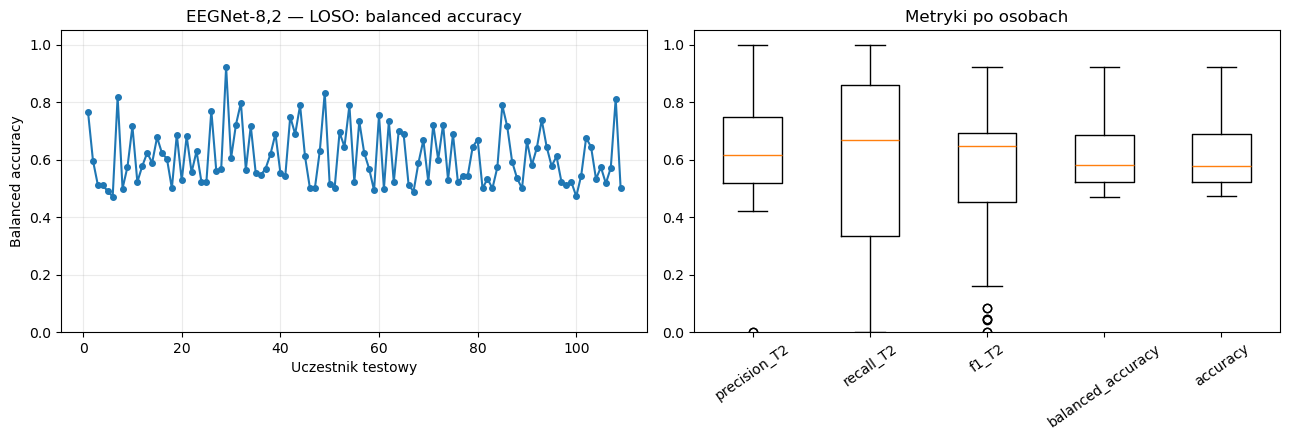

In [6]:
METRIC_COLS = ["precision_T2", "recall_T2", "f1_T2", "balanced_accuracy", "accuracy"]
summary_rows = []
for metric in METRIC_COLS:
    values = results_df[metric].to_numpy(dtype=float)
    n = len(values)
    mean, sd = float(np.mean(values)), float(np.std(values, ddof=1)) if n > 1 else 0.0
    if n <= 1 or np.isclose(sd, 0):
        low, high = mean, mean
    else:
        low, high = stats.t.interval(0.95, df=n - 1, loc=mean, scale=stats.sem(values))
    summary_rows.append({"metric": metric, "n_subjects": n,
                         "mean": mean, "std": sd,
                         "CI95_lower": float(low), "CI95_upper": float(high)})
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(OUTPUT_DIR / "podsumowanie_loso.csv", index=False)
print("Wyniki po osobach:")
display(results_df[["test_subject", "precision_T2", "recall_T2", "f1_T2",
                    "balanced_accuracy", "accuracy", "best_epoch",
                    "n_predicted_T2", "threshold_T2"]])
print("Podsumowanie per osoba (pełne LOSO):" if IS_FULL_LOSO else
      "Podsumowanie DIAGNOSTYCZNE (częściowe LOSO):")
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(results_df["test_subject"], results_df["balanced_accuracy"], marker="o", ms=4)
axes[0].set(xlabel="Uczestnik testowy", ylabel="Balanced accuracy", ylim=(0, 1.05),
            title="EEGNet-8,2 — LOSO: balanced accuracy")
axes[0].grid(alpha=0.25)
axes[1].boxplot([results_df[key].to_numpy() for key in METRIC_COLS],
                tick_labels=METRIC_COLS)
axes[1].set(title="Metryki po osobach", ylim=(0, 1.05))
axes[1].tick_params(axis="x", rotation=35)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "wyniki_loso.png", dpi=160, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

## 6. Macierz pomyłek, raport klasyfikacji i diagnostyka uczenia

              precision    recall  f1-score   support

   lewa dłoń       0.61      0.62      0.61      4950
  prawa dłoń       0.61      0.60      0.61      4894

    accuracy                           0.61      9844
   macro avg       0.61      0.61      0.61      9844
weighted avg       0.61      0.61      0.61      9844



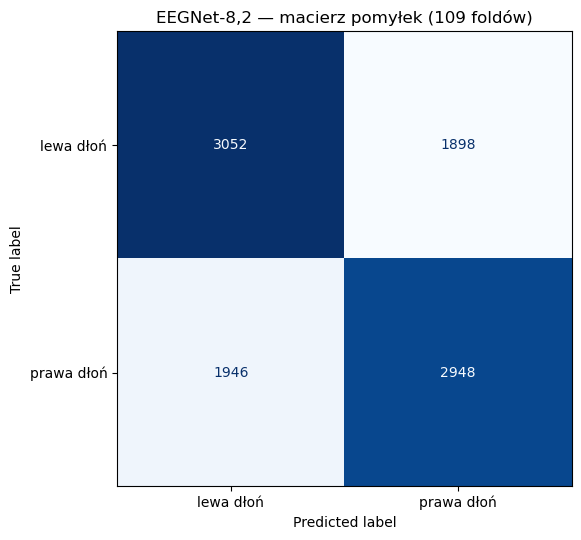

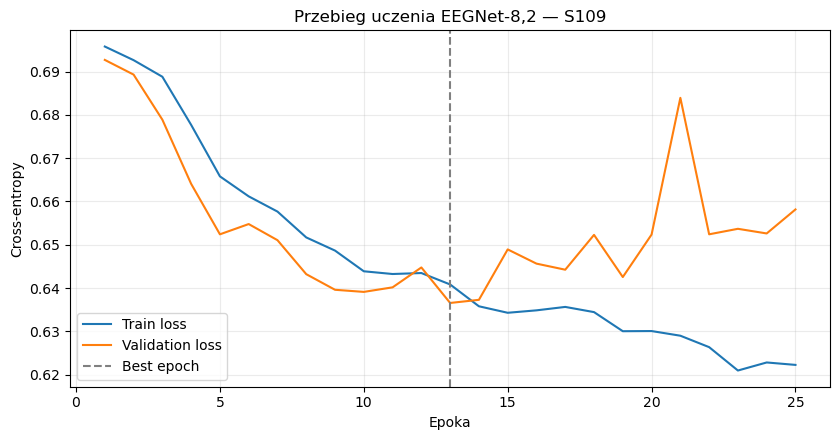

In [7]:
y_true_all = predictions_df["y_true"].to_numpy(dtype=np.int8)
y_pred_all = predictions_df["y_pred"].to_numpy(dtype=np.int8)
report = classification_report(y_true_all, y_pred_all, labels=[1, 2],
                               target_names=[CLASS_NAMES[1], CLASS_NAMES[2]],
                               zero_division=0)
print(report)
(OUTPUT_DIR / "raport_klasyfikacji.txt").write_text(report, encoding="utf-8")
cm = confusion_matrix(y_true_all, y_pred_all, labels=[1, 2])
fig, ax = plt.subplots(figsize=(6.0, 5.5))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=[CLASS_NAMES[1], CLASS_NAMES[2]]).plot(
    ax=ax, values_format="d", cmap="Blues", colorbar=False)
ax.set_title(f"EEGNet-8,2 — macierz pomyłek ({len(results_df)} foldów)")
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / "macierz_pomylek.png", dpi=160, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

plot_subject = (int(results_df["test_subject"].iloc[-1]) if TEST_SUBJECT_TO_SHOW is None
                else int(TEST_SUBJECT_TO_SHOW))
if plot_subject not in results_df["test_subject"].tolist():
    raise ValueError("Wybrany uczestnik nie ma wyników w aktualnym przebiegu.")
curve = history_df[(history_df["test_subject"] == plot_subject) &
                   (history_df["stage"] == "validation_fit")]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(curve["epoch"], curve["train_loss"], label="Train loss")
ax.plot(curve["epoch"], curve["val_loss"], label="Validation loss")
ax.axvline(int(results_df.set_index("test_subject").loc[plot_subject, "best_epoch"]),
           ls="--", color="gray", label="Best epoch")
ax.set(title=f"Przebieg uczenia EEGNet-8,2 — S{plot_subject:03d}",
       xlabel="Epoka", ylabel="Cross-entropy")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(OUTPUT_DIR / f"krzywa_uczenia_S{plot_subject:03d}.png",
                dpi=160, bbox_inches="tight")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

## 7. Predykcje i ponowne odtworzenie zapisanego modelu

In [ ]:
chosen = (predictions_df[predictions_df["test_subject"] == plot_subject]
          .sort_values("test_epoch").reset_index(drop=True))
print(f"Predykcje S{plot_subject:03d}: {len(chosen)} epok")
for row in chosen.head(N_SAMPLES).itertuples():
    print(f"Epoka {int(row.test_epoch):02d} / R{int(row.run):02d} | "
          f"prawda={CLASS_NAMES[int(row.y_true)]} | "
          f"predykcja={CLASS_NAMES[int(row.y_pred)]} | "
          f"P(T2)={float(row.probability_T2):.3f} | "
          f"próg={float(row.threshold_T2):.2f}")

if SAVE_MODELS:
    checkpoint_file = MODEL_DIR / f"S{plot_subject:03d}.pt"
    checkpoint = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
    if checkpoint["dataset_id"] != manifest["dataset_id"] or checkpoint["test_subject"] != plot_subject:
        raise AssertionError("Nieprawidłowy checkpoint / dataset_id.")
    inference_model = EEGNet82(checkpoint["n_channels"], checkpoint["n_times"]).to(DEVICE)
    inference_model.load_state_dict(checkpoint["model_state_dict"])
    inference_model.eval()
    verification_probs = predict_probability_T2(
        inference_model,
        chosen["global_epoch_index"].to_numpy(dtype=np.int64),
        checkpoint["mean_uv"].numpy(), checkpoint["std_uv"].numpy())
    if not np.allclose(verification_probs,
                       chosen["probability_T2"].to_numpy(dtype=float),
                       rtol=1e-5, atol=1e-7):
        raise AssertionError("Checkpoint nie odtwarza zapisanych prawdopodobieństw.")
    if not np.array_equal(
        labels_from_probability(verification_probs, checkpoint["threshold_T2"]),
        chosen["y_pred"].to_numpy(dtype=np.int8)):
        raise AssertionError("Checkpoint nie odtwarza zapisanych etykiet.")
    print("Zweryfikowano zapisany model na", len(chosen), "epokach osoby testowej.")

print("\nZapisane wyniki:", OUTPUT_DIR)
print("- wyniki_per_subject.csv, predykcje_epok.csv, podzialy_uczestnikow.csv")
print("- historia_uczenia.csv, podsumowanie_loso.csv, raport_klasyfikacji.txt")
if SAVE_PLOTS:
    print("- wyniki_loso.png, macierz_pomylek.png, krzywa_uczenia_Sxxx.png")
if SAVE_MODELS:
    print("- modele/Sxxx.pt (PyTorch state_dict + normalizacja + próg)")

Predykcje S109: 90 epok
Epoka 01 / R03 | prawda=lewa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 02 / R03 | prawda=prawa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 03 / R03 | prawda=lewa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 04 / R03 | prawda=prawa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 05 / R03 | prawda=prawa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 06 / R03 | prawda=lewa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 07 / R03 | prawda=lewa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 08 / R03 | prawda=prawa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 09 / R03 | prawda=lewa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Epoka 10 / R03 | prawda=prawa dłoń | predykcja=prawa dłoń | P(T2)=1.000 | próg=0.50
Zweryfikowano zapisany model na 90 epokach osoby testowej.

Zapisane wyniki: /home/wsl/phd/01_przygotowanie_danych_EEGMMIDB/wyniki_modeli/EEG